# thor_v3 dataset: exploratory analysis

The training dataset `compal/open_box_thor_v3_right6`, built by `scripts/prepare_dataset.py` from
`datasets/thor_v3.yaml`. It holds everything in thor_v2 (the `dataset_v2` front, left and right recordings and
the back-flap episodes of the first thor recordings) plus the 2026-11-26 recordings in `dataset_20261126/`, which
add front, left and right episodes. One flap per episode, three cameras, right-arm joint angles at 30 fps.

- The 2026-11-26 left and right flaps were recorded in the same episodes, one after the other. The build cuts each
  of those episodes where its label changes, so every flap is an episode of its own (section 4).
- **Nothing is held out** (`heldout_per_subset: 0`): every kept episode is trained on. The defective recordings
  are dropped (section 13).

Every number below is computed from the built dataset (section 4 also reads the raw recordings) when the notebook
runs, so after a rebuild, **Run All** refreshes it.

**To run it:** pick the project's `.venv` as the kernel. If VS Code can't install `ipykernel` there itself
(the `.venv` has no pip), run `uv pip install ipykernel` once in a terminal in the repo. The next cell then
installs anything else the notebook needs.

In [1]:
# Installs what this notebook needs into the Python running this kernel, only if something is missing.
# In the project's .venv everything is already there. A plain `!pip` would be the wrong tool here: the .venv
# has no pip, and the pip on the PATH belongs to miniconda, so this uses uv when it is installed.
# In a fresh environment, this repo's package brings lerobot and PyTorch with it (several GB).
import importlib.util
import shutil
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
NEEDED = {  # module: what to install
    "open_box_vla": f'-e "{REPO}"',  # this repo, which depends on lerobot[pi,dataset,training]==0.7.0
    "lerobot": '"lerobot[pi,dataset,training]==0.7.0"',
    "numpy": "numpy", "pandas": "pandas", "pyarrow": "pyarrow", "matplotlib": "matplotlib",
    "yaml": "pyyaml", "PIL": "pillow", "jinja2": "jinja2", "tqdm": "tqdm",
}
TO_INSTALL = " ".join(spec for module, spec in NEEDED.items() if importlib.util.find_spec(module) is None)
if not TO_INSTALL:
    print("All dependencies are installed.")
elif shutil.which("uv"):
    !uv pip install --python "{sys.executable}" {TO_INSTALL}
else:
    %pip install {TO_INSTALL}

All dependencies are installed.


In [2]:
import io
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from tqdm import TqdmWarning

from open_box_vla.dataset_specs import flap_shares  # the same balancing training uses

warnings.filterwarnings("ignore", category=TqdmWarning)  # lerobot's progress bars want ipywidgets

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SPEC_FILE = REPO / "datasets/thor_v3.yaml"
spec = yaml.safe_load(SPEC_FILE.read_text())
DATASETS = Path(os.environ.get("HF_LEROBOT_HOME", "/media/ai/aipc/Karel/compal_vla_models/lerobot_datasets"))
ROOT = DATASETS / spec["repo_id"]
RAW = Path(spec["raw_dir"])
NEW = "dataset_20261126/"                       # the folder of the 2026-11-26 recordings

FPS = 30
ORDER = spec["robot"]["flap_order"]             # the order the robot opens the flaps
REST = np.array(spec["robot"]["finish_pose"])   # every episode ends at this pose
HOME = np.array(spec["robot"]["start_poses"]["front"])
MOVED = 0.01                                    # rad: the arm has left a pose once a joint is this far from it

info = json.loads((ROOT / "meta/info.json").read_text())
stats = json.loads((ROOT / "meta/stats.json").read_text())
split = json.loads((ROOT / "meta/open_box_split.json").read_text())
prompt = {int(r.task_index): t for t, r in pd.read_parquet(ROOT / "meta/tasks.parquet").iterrows()}
data = pd.concat([pd.read_parquet(f) for f in sorted((ROOT / "data").glob("*/*.parquet"))], ignore_index=True)
data = data.sort_values("index").reset_index(drop=True)
data["flap"] = data["task_index"].map(lambda t: prompt[int(t)].split()[2])
STATE = np.stack(data["observation.state"].to_numpy()).astype(float)
FLAP = data["flap"].to_numpy()
HELD_OUT = set(split["val"])                    # empty: thor_v3 trains on every kept episode
SOURCE = {e["episode"]: e for e in split["episodes"]}
EPISODES = {int(e): {"state": STATE[g.index], "action": np.stack(g["action"].to_numpy()).astype(float),
                     "flap": g["flap"].iloc[0], "first_index": int(g["index"].iloc[0])}
            for e, g in data.groupby("episode_index")}

# Chart style: three colours from a palette checked for colour-blind readers, on a light background.
# Wherever both appear, blue is the earlier recordings and orange the 2026-11-26 ones.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
SESSION_COLOR = {"earlier": BLUE, "2026-11-26": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "legend.frameon": False,
})
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
print(f"{spec['repo_id']}: {info['total_episodes']} episodes, {info['total_frames']:,} frames, "
      f"{len(split['train'])} for training, {len(HELD_OUT)} held out; read from {ROOT}")

compal/open_box_thor_v3_right6: 83 episodes, 153,494 frames, 83 for training, 0 held out; read from /media/ai/aipc/Karel/compal_vla_models/lerobot_datasets/compal/open_box_thor_v3_right6


In [3]:
def still_time(s, from_end=False):
    """Seconds the arm stays within MOVED rad of its first (or last) pose."""
    s = s[::-1] if from_end else s
    moved = np.abs(s - s[0]).max(axis=1) > MOVED
    return (np.argmax(moved) if moved.any() else len(s)) / FPS


def resampled_path(s, n=200):
    """The moving part of an episode resampled to n points, to compare paths recorded at different speeds."""
    a, b = round(still_time(s) * FPS), len(s) - round(still_time(s, from_end=True) * FPS)
    s = s[a:b] if b > a + 10 else s
    t, tt = np.linspace(0, 1, len(s)), np.linspace(0, 1, n)
    return np.stack([np.interp(tt, t, s[:, j]) for j in range(s.shape[1])], axis=1)


def recorded_name(src):
    """An episode's name in its recording folder, as the YAML's drop list writes it: "3", or "1 left" for
    the left flap cut out of recorded episode 1."""
    return f"{src['recorded_episode']} {src['part']}" if "part" in src else str(src["recorded_episode"])


rows, paths = [], {}
for e, rec in EPISODES.items():
    s = rec["state"]
    step = np.abs(np.diff(s, axis=0))
    idle, hold = still_time(s), still_time(s, from_end=True)
    folder = SOURCE[e]["folder"]
    rows.append({
        "episode": e, "flap": rec["flap"], "folder": folder, "recorded_ep": recorded_name(SOURCE[e]),
        "session": "2026-11-26" if folder.startswith(NEW) else "earlier",
        "split": "held out" if e in HELD_OUT else "train",
        "length_s": len(s) / FPS, "start_idle_s": idle, "moving_s": len(s) / FPS - idle - hold, "end_hold_s": hold,
        "joint_travel_rad": step.sum(), "peak_joint_speed_rad_s": step.max() * FPS,
        "starts_at": "home" if np.abs(s[0] - HOME).max() < 1e-3 else "rest" if np.abs(s[0] - REST).max() < 1e-3 else "other",
        "ends_at_rest": bool(np.abs(s[-1] - REST).max() < 1e-3),
    })
    paths[e] = resampled_path(s)
ep = pd.DataFrame(rows).set_index("episode")
# How unusual each path is: median distance (mean |joint difference|, rad) to the other episodes of its flap
ep["path_distance_rad"] = [
    np.median([np.abs(paths[e] - paths[o]).mean() for o in ep.index[(ep.flap == f) & (ep.index != e)]])
    for e, f in ep.flap.items()]
ep["vs_typical"] = ep.path_distance_rad / ep.groupby("flap").path_distance_rad.transform("median")
TRAIN = ep.split == "train"
IS_NEW = ep.session == "2026-11-26"
train_frames = {f: int(round(ep[(ep.flap == f) & TRAIN].length_s.sum() * FPS)) for f in ORDER}
EXPONENT = float(spec.get("flap_balance_exponent", 1.0))
draw_share = flap_shares(train_frames, EXPONENT)
frame_share = {f: n / sum(train_frames.values()) for f, n in train_frames.items()}

# Raw labels of the folders that are cut by label: the flaps of each recorded episode and where its label
# changes (section 4, and to count the flaps of a dropped episode)
RAW_LABELS, RAW_LENGTH, LABEL_CHANGES = {}, {}, {}
for folder in spec.get("split_by_label") or {}:
    label_of = {int(r.task_index): t.split()[2] for t, r in pd.read_parquet(RAW / folder / "meta/tasks.parquet").iterrows()}
    raw = pd.concat([pd.read_parquet(f, columns=["episode_index", "frame_index", "task_index"])
                     for f in sorted((RAW / folder / "data").glob("*/*.parquet"))])
    for r, g in raw.sort_values(["episode_index", "frame_index"]).groupby("episode_index"):
        labels = g.task_index.to_numpy()
        RAW_LABELS[folder, int(r)] = [label_of[int(t)] for t in dict.fromkeys(labels)]
        RAW_LENGTH[folder, int(r)] = len(labels)
        LABEL_CHANGES[folder, int(r)] = (np.flatnonzero(labels[1:] != labels[:-1]) + 1).tolist()


def dropped_flaps(folder, name):
    """The flaps a dropped entry held: "0 right" is one flap of a cut episode; a whole episode of a folder
    that is cut by label held every flap it was recorded with."""
    episode, _, part = name.partition(" ")
    if part:
        return [part]
    return RAW_LABELS.get((folder, int(episode))) or list(ep.flap[ep.folder == folder].unique())


DROPPED = pd.DataFrame([{"folder": folder, "recorded_ep": name, "flaps": dropped_flaps(folder, name), "reason": why}
                        for folder, names in split["dropped"].items() for name, why in names.items()])
dropped_per_flap = pd.Series([f for flaps in DROPPED.flaps for f in flaps]).value_counts()
print(f"{len(ep)} episodes measured. Every one starts at its flap's recorded start pose: {(ep.starts_at != 'other').all()}; "
      f"every one ends at the rest pose: {ep.ends_at_rest.all()}")

83 episodes measured. Every one starts at its flap's recorded start pose: True; every one ends at the rest pose: True


## Summary

In [4]:
longest = ep.length_s.idxmax()
odd = ep.loc[ep.groupby("flap").vs_typical.idxmax().reindex(ORDER)]
wrist = np.abs(STATE[:, [3, 5]]).max()
from_split = ep[ep.folder.isin(list(spec.get("split_by_label") or {}))]
held =f"{int(TRAIN.sum())} train, {len(HELD_OUT)} held out" if HELD_OUT else "all of them trained on, none held out"
new_per_flap = [(f, int(((ep.flap == f) & IS_NEW).sum())) for f in ORDER]
lines = [
    f"- **{len(ep)} episodes, {ep.length_s.sum() / 60:.1f} min** ({held}); {len(DROPPED)} defective recorded "
    "episodes or flaps were dropped (section 13).",
    "- **Training episodes per flap:** " + ", ".join(f"{f} {int(((ep.flap == f) & TRAIN).sum())}" for f in ORDER) + ".",
    "- **From the 2026-11-26 recordings:** " + ", ".join(f"{f} {n}" for f, n in new_per_flap if n)
    + f" episodes ({ep[IS_NEW].length_s.sum() / 60:.1f} min). " + " and ".join(
        f"{n} {f}" for f, n in from_split.flap.value_counts().reindex(ORDER).dropna().astype(int).items())
    + " of them come from the left-then-right recordings (section 4).",
    f"- **Balance (exponent {EXPONENT:g}):** " + ", ".join(f"{f} {frame_share[f]:.0%} of frames → {draw_share[f]:.0%} of draws" for f in ORDER) + ".",
    f"- **Longest episode:** {ep.length_s[longest]:.0f} s ({ep.flap[longest]}, episode {longest}); the robot's default per-flap timeout is 90 s.",
    f"- **Still at the start:** {ep.start_idle_s.min():.1f}–{ep.start_idle_s.max():.1f} s; "
    f"**still at the end (rest pose):** {ep.end_hold_s.min():.1f}–{ep.end_hold_s.max():.1f} s.",
    "- **Most unusual path per flap** (1 = typical): " + ", ".join(f"{r.flap} episode {e} ({r.vs_typical:.2f}x)" for e, r in odd.iterrows()) + ".",
    f"- **Joints 4 and 6** reach ±{wrist:.2f} rad (±{np.degrees(wrist):.0f}°); the front movement turns them the other way from the other flaps.",
]
display(Markdown("\n".join(lines)))

- **83 episodes, 85.3 min** (all of them trained on, none held out); 9 defective recorded episodes or flaps were dropped (section 13).
- **Training episodes per flap:** front 18, back 27, left 20, right 18.
- **From the 2026-11-26 recordings:** front 5, left 13, right 11 episodes (30.9 min). 13 left and 11 right of them come from the left-then-right recordings (section 4).
- **Balance (exponent 0.43):** front 28% of frames → 26% of draws, back 28% of frames → 26% of draws, left 24% of frames → 25% of draws, right 20% of frames → 23% of draws.
- **Longest episode:** 90 s (front, episode 14); the robot's default per-flap timeout is 90 s.
- **Still at the start:** 1.5–5.5 s; **still at the end (rest pose):** 0.8–7.5 s.
- **Most unusual path per flap** (1 = typical): front episode 11 (1.44x), back episode 22 (1.48x), left episode 72 (1.38x), right episode 52 (1.49x).
- **Joints 4 and 6** reach ±3.02 rad (±173°); the front movement turns them the other way from the other flaps.

## 1. Format

In [5]:
cams = [k.split(".")[-1] for k in info["features"] if k.startswith("observation.images.")]
cam = info["features"][f"observation.images.{cams[0]}"]
display(pd.DataFrame([
    ("Episodes", f"{info['total_episodes']}: " + (f"{int(TRAIN.sum())} train, {len(HELD_OUT)} held out ({sorted(HELD_OUT)})"
                                                  if HELD_OUT else "all for training, none held out")),
    ("Frames", f"{info['total_frames']:,} = {info['total_frames'] / FPS / 60:.1f} min at {info['fps']} fps"),
    ("Cameras", ", ".join(cams)),
    ("Image size", f"{cam['shape'][1]} x {cam['shape'][0]} px, {cam.get('info', {}).get('video.codec', '?')} video"),
    ("State and action", "6 right-arm joint angles (rad): " + ", ".join(info["features"]["action"]["names"])),
    ("Prompts", " / ".join(prompt[i] for i in sorted(prompt))),
    ("Flap order on the robot", " → ".join(ORDER)),
    ("Recording folders", f"{len(spec['subsets'])}, in {RAW}"),
    ("Built from", f"datasets/{SPEC_FILE.name}"),
], columns=["", "value"]).set_index(""))

,value
,
Episodes,"83: all for training, none held out"
Frames,"153,494 = 85.3 min at 30 fps"
Cameras,"head, wrist_right, knife_left"
Image size,"640 x 480 px, av1 video"
State and action,"6 right-arm joint angles (rad): arm_right_joint1, arm_right_joint2, arm_right_joint3, arm_right_joint4, arm_right_jo..."
Prompts,open the back flap / open the front flap / open the left flap / open the right flap
Flap order on the robot,front → back → left → right
Recording folders,"7, in /media/ai/aipc/Karel/Mocap/datasets"
Built from,datasets/thor_v3.yaml


## 2. How much data each flap has

`recorded` counts every flap that was recorded and `dropped` the defective ones left out (section 13); a dropped
left-then-right episode counts once for each of its flaps. `already open (recordings)` comes from the camera images
(see the comments in `datasets/thor_v3.yaml`). Orange would mark a flap whose box looks different on the robot than
in its recordings.

In [6]:
OPEN_WHEN_RECORDED = {"front": "nothing (box closed)", "back": "front (recorded episodes 4-14) or nothing (0-3)",
                      "left": "front, back", "right": "front, back, left"}
flaps = pd.DataFrame({
    "robot order": range(1, len(ORDER) + 1),
    "folders": [", ".join(dict.fromkeys(ep[ep.flap == f].folder)) for f in ORDER],
    "recorded": [int((ep.flap == f).sum() + dropped_per_flap.get(f, 0)) for f in ORDER],
    "dropped": [int(dropped_per_flap.get(f, 0)) for f in ORDER],
    "train": [int(((ep.flap == f) & TRAIN).sum()) for f in ORDER],
    "held out": [int(((ep.flap == f) & ~TRAIN).sum()) for f in ORDER],
    "kept from 2026-11-26": [int(((ep.flap == f) & IS_NEW).sum()) for f in ORDER],
    "minutes": [ep[ep.flap == f].length_s.sum() / 60 for f in ORDER],
    "length min / median / max (s)": [" / ".join(f"{v:.0f}" for v in ep[ep.flap == f].length_s.agg(["min", "median", "max"])) for f in ORDER],
    "starts at": [", ".join(sorted(set(ep[ep.flap == f].starts_at))) + " pose" for f in ORDER],
    "already open (recordings)": [OPEN_WHEN_RECORDED.get(f, "?") for f in ORDER],
    "already open (robot)": [", ".join(ORDER[:i]) or "nothing (box closed)" for i in range(len(ORDER))],
}, index=pd.Index(ORDER, name="flap"))


def mismatch(row):
    differs = row["already open (recordings)"].split(" (")[0] != row["already open (robot)"].split(" (")[0]
    return ["background-color: #fbd9c9; color: #0b0b0b" if differs and c == "already open (robot)" else "" for c in row.index]


display(flaps.style.format({"minutes": "{:.1f}"}).apply(mismatch, axis=1))

,robot order,folders,recorded,dropped,train,held out,kept from 2026-11-26,minutes,length min / median / max (s),starts at,already open (recordings),already open (robot)
flap,,,,,,,,,,,,
front,1,"dataset_v2/thor_box_front_newmovement, dataset_20261126/thor_box_flapfront_newmovement1",22,4,18,0,5,24.0,68 / 80 / 90,home pose,nothing (box closed),nothing (box closed)
back,2,"thor_box2_back, thor_test1_back",30,3,27,0,0,23.8,43 / 51 / 69,rest pose,front (recorded episodes 4-14) or nothing (0-3),front
left,3,"dataset_v2/thor_box_flapleft_newmovement, dataset_20261126/thor_box_flapright_newmovement",21,1,20,0,13,20.3,55 / 58 / 76,rest pose,"front, back","front, back"
right,4,"dataset_v2/thor_box_flapright_newmovement, dataset_20261126/thor_box_flapright_newmovement",20,2,18,0,11,17.2,50 / 57 / 70,rest pose,"front, back, left","front, back, left"


## 3. Balance: how often training sees each flap

Training draws frames with weight n<sup>exponent</sup> per flap (`flap_balance_exponent` in the YAML, applied by
`scripts/train_with_heldout.py`), so a flap with fewer frames is drawn a little more often than its share of the frames.

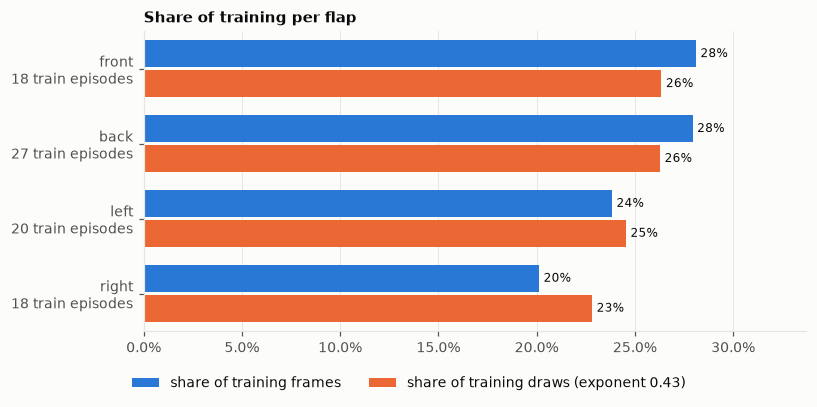

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.7))
y, h = np.arange(len(ORDER)), 0.36
b1 = ax.barh(y - h / 2 - 0.02, [frame_share[f] for f in ORDER], height=h, color=BLUE, label="share of training frames")
b2 = ax.barh(y + h / 2 + 0.02, [draw_share[f] for f in ORDER], height=h, color=ORANGE,
             label=f"share of training draws (exponent {EXPONENT:g})")
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f"{b.get_width():.0%}" for b in bars], padding=3, color=INK, fontsize=8)
ax.set_yticks(y, [f"{f}\n{int(((ep.flap == f) & TRAIN).sum())} train episodes" for f in ORDER])
ax.set_ylim(len(ORDER) - 0.5, -0.5)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, max(max(frame_share.values()), max(draw_share.values())) * 1.2)
ax.grid(axis="y", visible=False)
ax.set_title("Share of training per flap")
fig.legend(handles=[b1, b2], loc="lower center", ncols=2, bbox_to_anchor=(0.5, 0))
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

## 4. The left-then-right recordings: where each was cut

Each episode of `dataset_20261126/thor_box_flapright_newmovement` opens the left flap, goes back to the rest pose,
then opens the right flap; the label was switched in between. The build cuts every episode where its label changes,
or at the time `split_by_label` in the YAML gives ("(YAML)"), and stops if the arm is not resting at the finish
pose there. Each bar is one recorded episode; the black tick is where the label changed in the recording.
`at rest around the cut` is how long the arm stands still at the rest pose before and after the cut.

**`dataset_20261126/thor_box_flapright_newmovement`**: 14 recorded episodes, now 13 left and 11 right episodes of the dataset.

,length (s),label changed at (s),cut at (s),left,right,at rest around the cut (s)
recorded episode,,,,,,
0,106.1,65.5,65.5,"episode 59, 0.0–65.5 s",dropped: cut off before the arm is back at the rest pose,-
1,116.0,42.3,56.6 (YAML),"episode 60, 0.0–56.6 s","episode 61, 56.6–116.0 s","1.6 before, 1.5 after"
2,112.6,60.8,-,dropped: goes from the left flap straight to the right one without returning to the rest pose in between,dropped: goes from the left flap straight to the right one without returning to the rest pose in between,-
3,113.4,55.6,55.6,"episode 62, 0.0–55.6 s","episode 63, 55.6–113.4 s","2.2 before, 3.2 after"
4,121.3,59.3,59.3,"episode 64, 0.0–59.3 s","episode 65, 59.3–121.3 s","0.9 before, 3.7 after"
5,135.4,65.9,65.9,"episode 66, 0.0–65.9 s","episode 67, 65.9–135.4 s","3.2 before, 3.3 after"
6,120.9,66.1,66.1,"episode 68, 0.0–66.1 s","episode 69, 66.1–120.9 s","2.4 before, 3.5 after"
7,110.9,60.4,60.4,"episode 70, 0.0–60.4 s","episode 71, 60.4–110.9 s","1.2 before, 2.9 after"
8,134.0,75.6,75.6,"episode 72, 0.0–75.6 s","episode 73, 75.6–134.0 s","4.7 before, 3.6 after"


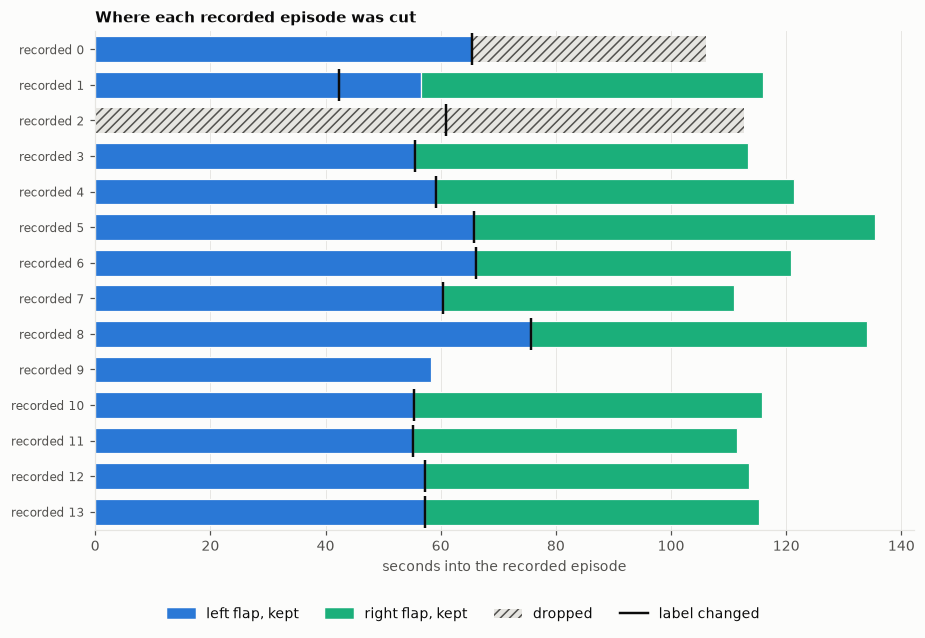

In [8]:
PART_COLOR = {"left": BLUE, "right": AQUA}
for folder, yaml_cuts in (spec.get("split_by_label") or {}).items():
    pieces = {(SOURCE[e]["recorded_episode"], SOURCE[e]["part"]): e for e in ep.index[ep.folder == folder]}
    gone = split["dropped"].get(folder, {})
    recs = sorted(r for f, r in RAW_LENGTH if f == folder)
    bars, rows = {}, []
    for r in recs:
        bounds = [0] + LABEL_CHANGES[folder, r] + [RAW_LENGTH[folder, r]]
        parts = []
        for k, flap in enumerate(RAW_LABELS[folder, r]):
            e = pieces.get((r, flap))
            if e is not None:
                a, b = SOURCE[e]["recorded_frames"]
            else:  # dropped: from the end of the flap before it to the next label change
                a, b = (parts[-1][2] if parts else 0), bounds[k + 1]
            parts.append((flap, a, b, e))
        bars[r] = parts
        whole_dropped = str(r) in gone
        row = {"recorded episode": r, "length (s)": RAW_LENGTH[folder, r] / FPS,
               "label changed at (s)": ", ".join(f"{c / FPS:.1f}" for c in LABEL_CHANGES[folder, r]) or "-",
               "cut at (s)": "-" if whole_dropped or len(parts) < 2 else
               ", ".join(f"{a / FPS:.1f}" for _, a, _, _ in parts[1:]) + (" (YAML)" if r in yaml_cuts else "")}
        for flap, a, b, e in parts:
            why = gone.get(str(r)) or gone.get(f"{r} {flap}")
            row[flap] = f"dropped: {why}" if e is None else f"episode {e}, {a / FPS:.1f}–{b / FPS:.1f} s"
        kept = [e for _, _, _, e in parts if e is not None]
        row["at rest around the cut (s)"] = (f"{ep.end_hold_s[kept[0]]:.1f} before, {ep.start_idle_s[kept[1]]:.1f} after"
                                             if len(kept) == 2 else "-")
        rows.append(row)
    n_flap = ep[ep.folder == folder].flap.value_counts()
    display(Markdown(f"**`{folder}`**: {len(recs)} recorded episodes, now "
                     + " and ".join(f"{n_flap[f]} {f}" for f in ORDER if f in n_flap) + " episodes of the dataset."))
    display(pd.DataFrame(rows).set_index("recorded episode").fillna("-").style.format({"length (s)": "{:.1f}"}))

    fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(recs) + 1.6))
    for i, r in enumerate(recs):
        for flap, a, b, e in bars[r]:
            kept = e is not None
            ax.barh(i, (b - a) / FPS, left=a / FPS, height=0.72, color=PART_COLOR.get(flap, INK2) if kept else GRID,
                    hatch=None if kept else "////", edgecolor=SURFACE if kept else INK2, linewidth=0.8 if kept else 0)
        for c in LABEL_CHANGES[folder, r]:
            ax.plot([c / FPS] * 2, [i - 0.45, i + 0.45], color=INK, lw=1.6, solid_capstyle="butt", zorder=4)
    ax.set_yticks(range(len(recs)), [f"recorded {r}" for r in recs], fontsize=8)
    ax.set_ylim(len(recs) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("seconds into the recorded episode")
    ax.set_title("Where each recorded episode was cut")
    fig.legend(handles=[Patch(color=BLUE, label="left flap, kept"), Patch(color=AQUA, label="right flap, kept"),
                        Patch(facecolor=GRID, edgecolor=INK2, hatch="////", lw=0, label="dropped"),
                        Line2D([], [], color=INK, lw=1.6, label="label changed")],
               loc="lower center", ncols=4, bbox_to_anchor=(0.5, 0))
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()

## 5. Episode timing

Each bar is one episode: how long the arm stays still at the start, moves, and stands at the rest pose at
the end (the robot's finish detector needs about 1 s of standing still there). `new` marks the 2026-11-26
recordings. The numbers are in the table in section 6.

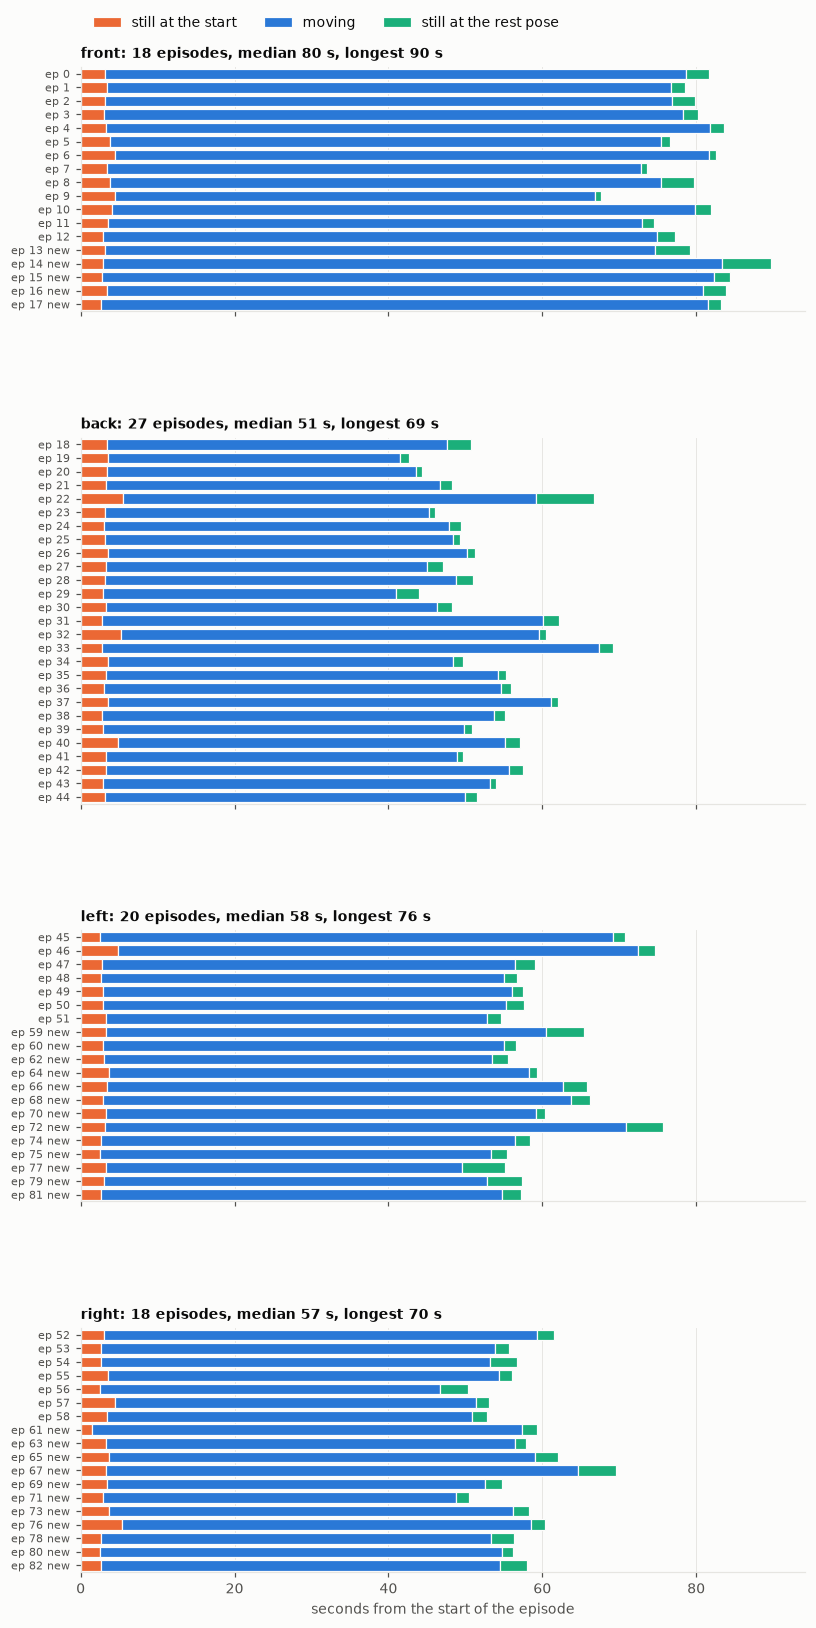

In [9]:
counts = [int((ep.flap == f).sum()) for f in ORDER]
fig, axes = plt.subplots(len(ORDER), 1, figsize=(8.5, 0.19 * len(ep) + 2), sharex=True,
                         gridspec_kw={"height_ratios": counts, "hspace": 0.45})
for ax, f in zip(axes, ORDER):
    g = ep[ep.flap == f]
    y = np.arange(len(g))
    kw = dict(height=0.78, edgecolor=SURFACE, linewidth=0.8)
    ax.barh(y, g.start_idle_s, color=ORANGE, label="still at the start", **kw)
    ax.barh(y, g.moving_s, left=g.start_idle_s, color=BLUE, label="moving", **kw)
    ax.barh(y, g.end_hold_s, left=g.start_idle_s + g.moving_s, color=AQUA, label="still at the rest pose", **kw)
    ax.set_yticks(y, [f"ep {e}" + (" new" if r.session == "2026-11-26" else "") + (" (held out)" if r.split == "held out" else "")
                      for e, r in g.iterrows()], fontsize=7)
    ax.set_ylim(len(g) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{f}: {len(g)} episodes, median {g.length_s.median():.0f} s, longest {g.length_s.max():.0f} s", fontsize=9)
axes[-1].set_xlabel("seconds from the start of the episode")
axes[0].legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.1))
plt.show()

## 6. Every episode

`recorded_ep` is the episode's number in its recording folder ("1 left": the left flap cut out of recorded
episode 1). `path_distance_rad`: median distance from this episode's path to the other episodes of the same flap
(paths resampled to the same length, mean |joint difference|). `vs_typical` divides it by the flap's median, so 1
is typical and darker orange is more unusual.

In [10]:
cols = ["flap", "folder", "recorded_ep", "session"] + (["split"] if HELD_OUT else []) + [
    "length_s", "start_idle_s", "moving_s", "end_hold_s", "joint_travel_rad", "peak_joint_speed_rad_s",
    "path_distance_rad", "vs_typical"]
fmt = {c: "{:.1f}" for c in ["length_s", "start_idle_s", "moving_s", "end_hold_s", "joint_travel_rad"]}
fmt |= {"peak_joint_speed_rad_s": "{:.2f}", "path_distance_rad": "{:.3f}", "vs_typical": "{:.2f}"}
display(ep[cols].style.format(fmt)
        .background_gradient(subset=["vs_typical"], cmap="Oranges", vmin=0.8, vmax=1.8)
        .apply(lambda r: ["font-weight: bold" if r.name in HELD_OUT else ""] * len(r), axis=1))

,flap,folder,recorded_ep,session,length_s,start_idle_s,moving_s,end_hold_s,joint_travel_rad,peak_joint_speed_rad_s,path_distance_rad,vs_typical
episode,,,,,,,,,,,,
0,front,dataset_v2/thor_box_front_newmovement,1,earlier,81.7,3.1,75.5,3.0,26.1,0.37,0.170,0.95
1,front,dataset_v2/thor_box_front_newmovement,2,earlier,78.5,3.5,73.2,1.8,26.3,0.34,0.192,1.07
2,front,dataset_v2/thor_box_front_newmovement,3,earlier,79.8,3.2,73.7,3.0,26.6,0.32,0.142,0.79
3,front,dataset_v2/thor_box_front_newmovement,4,earlier,80.2,3.0,75.4,1.9,29.5,1.08,0.187,1.05
4,front,dataset_v2/thor_box_front_newmovement,5,earlier,83.6,3.3,78.5,1.8,28.9,0.35,0.160,0.89
5,front,dataset_v2/thor_box_front_newmovement,6,earlier,76.6,3.8,71.6,1.3,26.6,0.36,0.223,1.24
6,front,dataset_v2/thor_box_front_newmovement,7,earlier,82.6,4.4,77.3,0.9,29.2,0.38,0.161,0.90
7,front,dataset_v2/thor_box_front_newmovement,8,earlier,73.7,3.4,69.4,0.8,25.4,0.32,0.162,0.91
8,front,dataset_v2/thor_box_front_newmovement,9,earlier,79.7,3.8,71.7,4.2,25.7,0.32,0.161,0.90


## 7. Joint movements: earlier and 2026-11-26 recordings

Every episode's six joint angles over time, one column per flap: the earlier recordings in blue, the 2026-11-26
ones in orange, the rest pose dashed. Episodes that follow the same path lie on top of each other, so orange lines
inside the blue bundle mean the new recordings repeat the movement of the earlier ones.

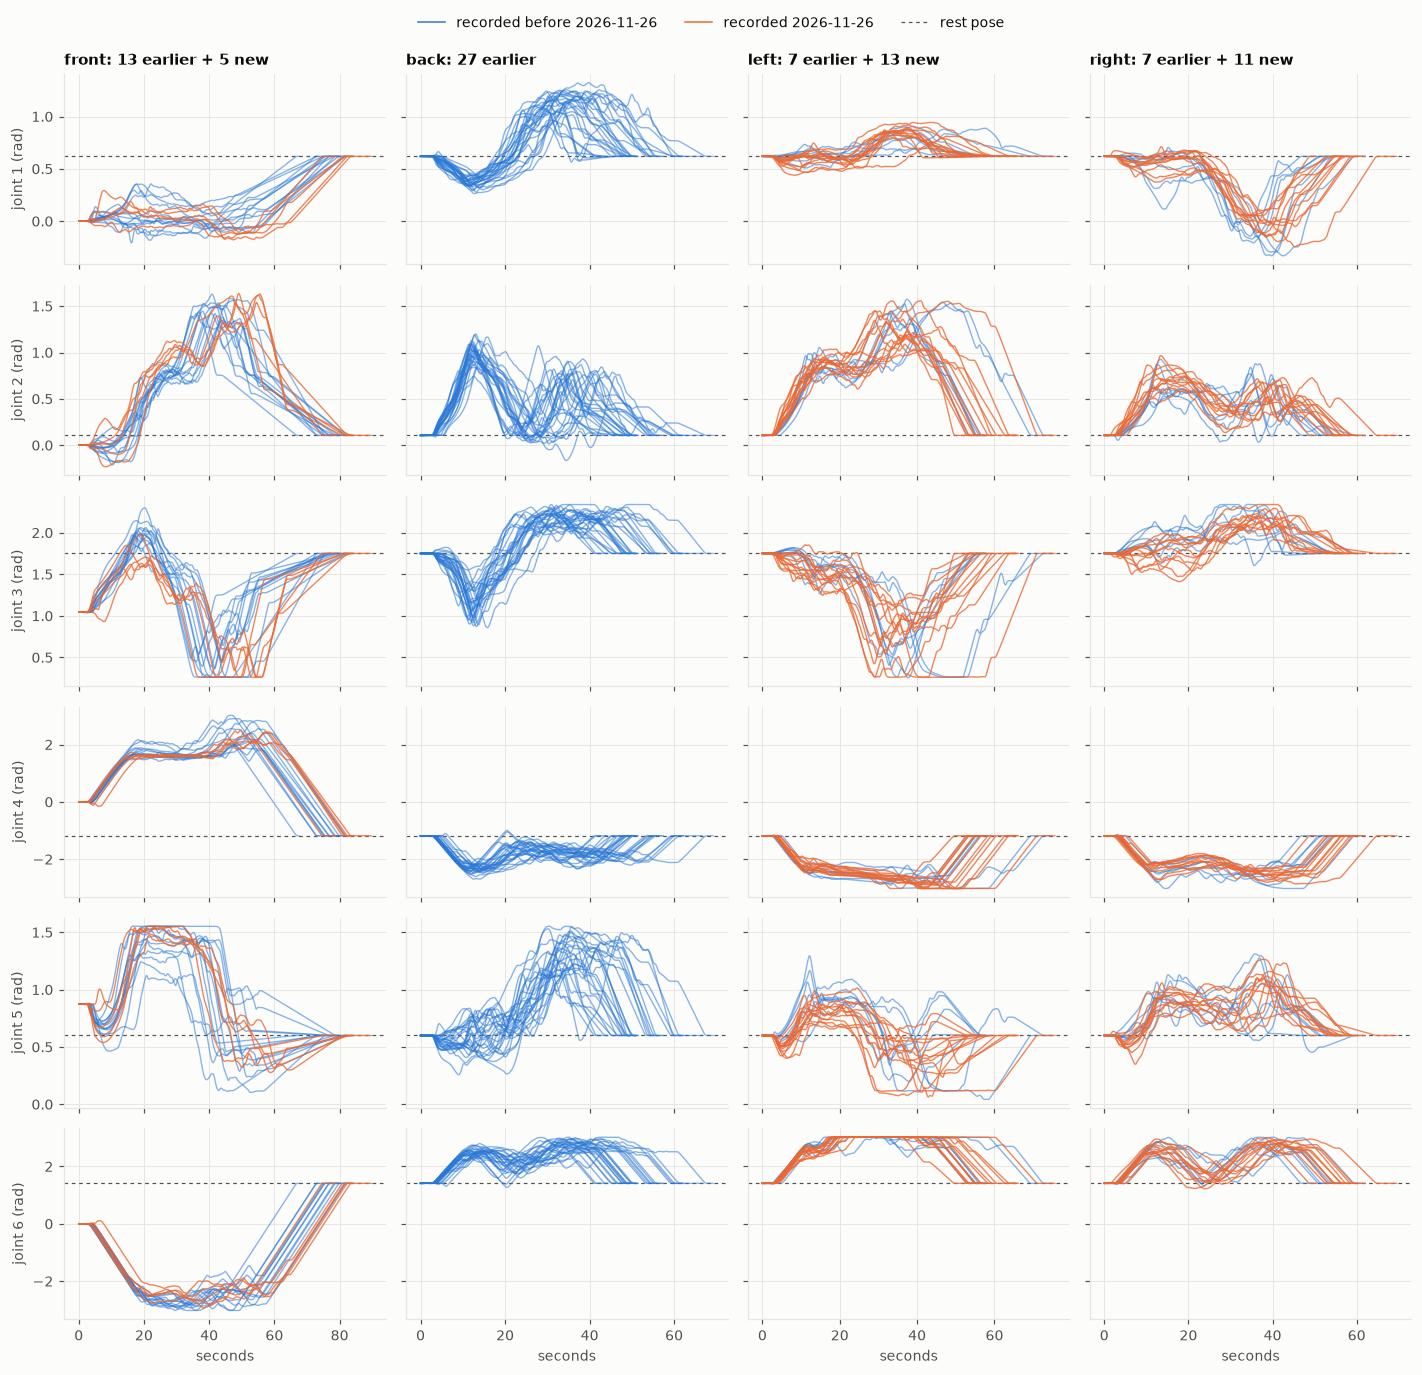

In [11]:
fig, axes = plt.subplots(6, len(ORDER), figsize=(13, 12.5), sharex="col", sharey="row")
for c, f in enumerate(ORDER):
    g = ep[ep.flap == f].sort_values("session", key=lambda s: s == "2026-11-26")  # the new ones drawn on top
    for e, r in g.iterrows():
        s, new = EPISODES[e]["state"], r.session == "2026-11-26"
        t = np.arange(len(s)) / FPS
        for j in range(6):
            axes[j, c].plot(t, s[:, j], color=SESSION_COLOR[r.session], lw=0.9, alpha=0.8 if new else 0.55,
                            zorder=3 if new else 2)
    for j in range(6):
        axes[j, c].axhline(REST[j], color=INK2, lw=0.8, ls=(0, (3, 3)), zorder=1)
    n_new = int((g.session == "2026-11-26").sum())
    axes[0, c].set_title(f"{f}: {len(g) - n_new} earlier" + (f" + {n_new} new" if n_new else ""))
    axes[-1, c].set_xlabel("seconds")
for j in range(6):
    axes[j, 0].set_ylabel(f"joint {j + 1} (rad)")
fig.legend(handles=[Line2D([], [], color=BLUE, lw=1, label="recorded before 2026-11-26"),
                    Line2D([], [], color=ORANGE, lw=1, label="recorded 2026-11-26"),
                    Line2D([], [], color=INK2, lw=0.8, ls=(0, (3, 3)), label="rest pose")],
           loc="upper center", ncols=3, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.975))
plt.show()

## 8. Speed through an episode

How fast the fastest joint moves (0.5 s average) over each episode, with time as a share of the episode so
short and long ones line up. Line: median of a flap's episodes from one recording session; band: their middle half.

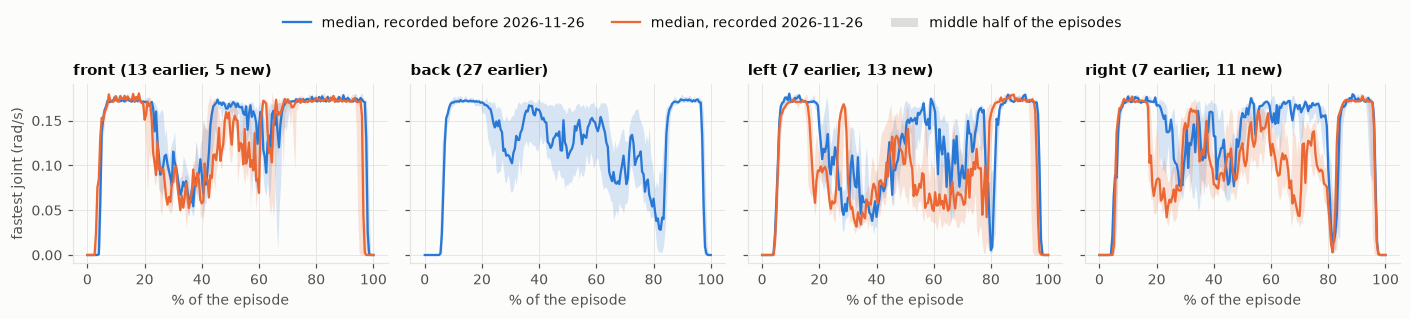

In [12]:
fig, axes = plt.subplots(1, len(ORDER), figsize=(13, 2.9), sharey=True)
pct = np.linspace(0, 100, 201)
for ax, f in zip(axes, ORDER):
    for session, color in SESSION_COLOR.items():
        curves = []
        for e in ep.index[(ep.flap == f) & (ep.session == session)]:
            speed = np.abs(np.diff(EPISODES[e]["state"], axis=0)).max(axis=1) * FPS
            speed = np.convolve(speed, np.ones(15) / 15, mode="same")
            curves.append(np.interp(pct, np.linspace(0, 100, len(speed)), speed))
        if len(curves) < 2:
            continue
        q25, q50, q75 = np.percentile(np.array(curves), [25, 50, 75], axis=0)
        ax.fill_between(pct, q25, q75, color=color, alpha=0.18, lw=0)
        ax.plot(pct, q50, color=color, lw=1.5)
    n = ep[ep.flap == f].session.value_counts()
    ax.set_title(f"{f} ({n.get('earlier', 0)} earlier" + (f", {n['2026-11-26']} new)" if "2026-11-26" in n else ")"))
    ax.set_xlabel("% of the episode")
axes[0].set_ylabel("fastest joint (rad/s)")
fig.legend(handles=[Line2D([], [], color=BLUE, lw=1.5, label="median, recorded before 2026-11-26"),
                    Line2D([], [], color=ORANGE, lw=1.5, label="median, recorded 2026-11-26"),
                    Patch(color=INK2, alpha=0.18, lw=0, label="middle half of the episodes")],
           loc="upper center", ncols=3, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## 9. Joint ranges

Where each flap's joint angles lie: thin line from minimum to maximum, thick bar from the 1st to the 99th
percentile, dot at the median. The grey band is the range the model normalises each joint with
(1st–99th percentile over the whole dataset), mapped to -1…1.

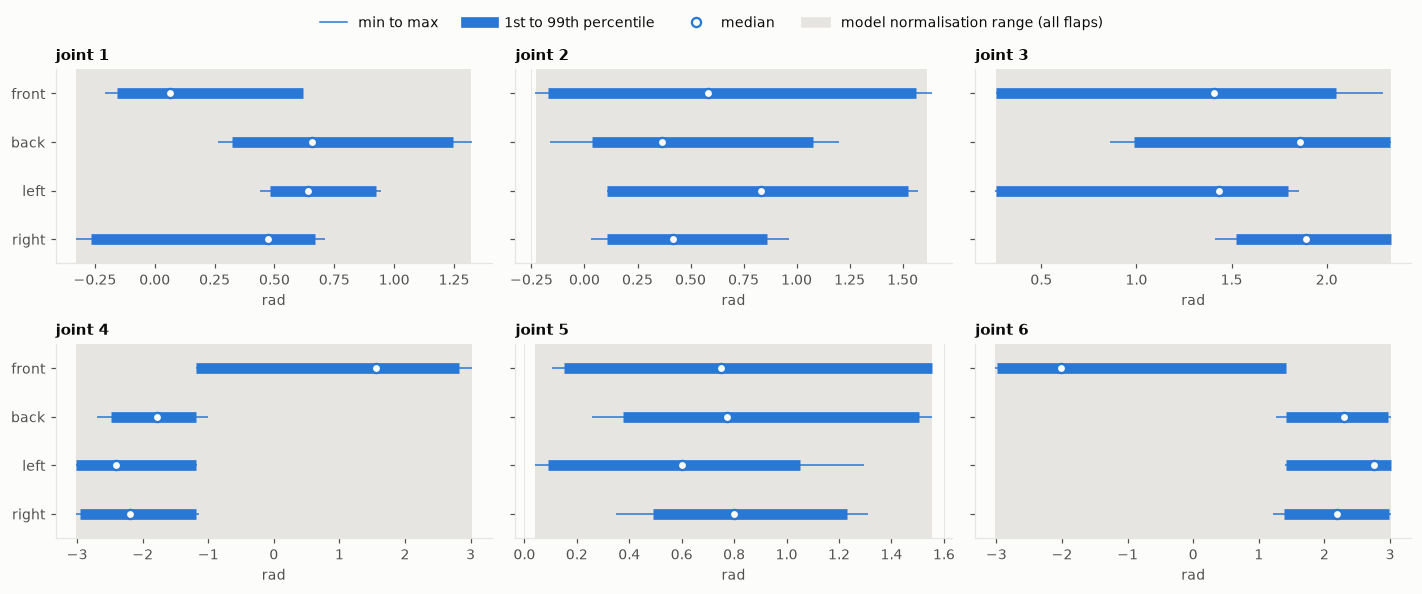

,q01 (rad),q99 (rad)
joint 1,-0.328,1.320
joint 2,-0.229,1.616
joint 3,0.262,2.339
joint 4,-3.020,3.019
joint 5,0.042,1.554
joint 6,-3.020,3.020


In [13]:
st = stats["observation.state"]
fig, axes = plt.subplots(2, 3, figsize=(13, 5.4), sharey=True)
for j, ax in enumerate(axes.flat):
    ax.axvspan(st["q01"][j], st["q99"][j], color=GRID, lw=0, zorder=0)
    for i, f in enumerate(ORDER):
        x = STATE[FLAP == f, j]
        q01, med, q99 = np.quantile(x, [0.01, 0.5, 0.99])
        ax.plot([x.min(), x.max()], [i, i], color=BLUE, lw=1, solid_capstyle="butt", zorder=2)
        ax.plot([q01, q99], [i, i], color=BLUE, lw=7, solid_capstyle="butt", zorder=3)
        ax.plot(med, i, "o", color=SURFACE, mec=BLUE, mew=1.5, ms=6, zorder=4)
    ax.set_title(f"joint {j + 1}")
    ax.set_yticks(range(len(ORDER)), ORDER)
    ax.set_ylim(len(ORDER) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("rad")
fig.legend(handles=[Line2D([], [], color=BLUE, lw=1, label="min to max"),
                    Line2D([], [], color=BLUE, lw=7, label="1st to 99th percentile"),
                    Line2D([], [], color=SURFACE, marker="o", mec=BLUE, mew=1.5, ms=6, lw=0, label="median"),
                    Patch(color=GRID, label="model normalisation range (all flaps)")],
           loc="upper center", ncols=4, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
display(pd.DataFrame({"q01 (rad)": st["q01"], "q99 (rad)": st["q99"]}, index=[f"joint {j + 1}" for j in range(6)])
        .style.format("{:.3f}"))

## 10. Unusual paths

Each dot is one episode's `vs_typical` from section 6: blue for the earlier recordings, orange for the 2026-11-26
ones. The dashed line at 1.6x is the limit used when choosing which episodes to drop; episodes above 1.3x are
labelled with their recorded number.

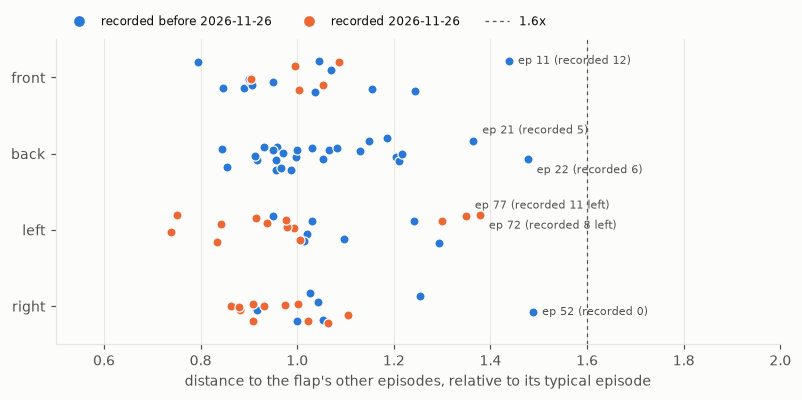

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
rng = np.random.default_rng(0)
for i, f in enumerate(ORDER):
    g = ep[ep.flap == f]
    yj = i + rng.uniform(-0.22, 0.22, len(g))
    for session, color in SESSION_COLOR.items():
        m = (g.session == session).to_numpy()
        ax.scatter(g.vs_typical[m], yj[m], s=36, color=color, edgecolor=SURFACE, lw=0.8, zorder=3)
    marked = sorted((r.vs_typical, yy, e, r.recorded_ep) for (e, r), yy in zip(g.iterrows(), yj) if r.vs_typical > 1.3)
    for k, (x, yy, e, name) in enumerate(marked):
        dy = 0 if len(marked) == 1 else 7 if k % 2 == 0 else -7  # points: neighbouring labels go up and down
        ax.annotate(f"ep {e} (recorded {name})", (x, yy), xytext=(6, dy), textcoords="offset points",
                    va="center", fontsize=7, color=INK2)
ax.axvline(1.6, color=INK2, lw=0.8, ls=(0, (3, 3)))
ax.set_yticks(range(len(ORDER)), ORDER)
ax.set_ylim(len(ORDER) - 0.5, -0.5)
ax.set_xlim(left=min(0.5, ep.vs_typical.min() - 0.05), right=max(2.0, ep.vs_typical.max() + 0.4))
ax.grid(axis="y", visible=False)
ax.set_xlabel("distance to the flap's other episodes, relative to its typical episode")
ax.legend(handles=[Line2D([], [], color=BLUE, marker="o", lw=0, label="recorded before 2026-11-26"),
                   Line2D([], [], color=ORANGE, marker="o", lw=0, label="recorded 2026-11-26"),
                   Line2D([], [], color=INK2, lw=0.8, ls=(0, (3, 3)), label="1.6x")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncols=3, fontsize=8)
plt.show()

## 11. Action vs state

The action is the joint target; the measured state reaches it about 7 frames (0.23 s) later. For each folder:
the lag that fits best, and how far the action is from the state 7 frames later (largest joint).

In [15]:
rows = []
for folder in dict.fromkeys(ep.folder):
    lags, d7 = [], []
    for e in ep.index[ep.folder == folder]:
        s, a = EPISODES[e]["state"], EPISODES[e]["action"]
        err = {L: np.abs(a[:-L] - s[L:]).mean() for L in range(1, 16)}
        lags.append(min(err, key=err.get))
        d7.append(np.abs(a[:-7] - s[7:]).max(axis=1))
    d7 = np.concatenate(d7)
    rows.append({"folder": folder, "best lag (frames), per episode": ", ".join(f"{k}: {v}" for k, v in sorted(pd.Series(lags).value_counts().items())),
                 "median gap at 7 frames (rad)": np.median(d7), "99th percentile (rad)": np.percentile(d7, 99),
                 "frames within 0.005 rad": (d7 < 0.005).mean()})
display(pd.DataFrame(rows).set_index("folder").style.format(
    {"median gap at 7 frames (rad)": "{:.4f}", "99th percentile (rad)": "{:.4f}", "frames within 0.005 rad": "{:.1%}"}))

,"best lag (frames), per episode",median gap at 7 frames (rad),99th percentile (rad),frames within 0.005 rad
folder,,,,
dataset_v2/thor_box_front_newmovement,7: 13,0.0015,0.0050,99.0%
dataset_20261126/thor_box_flapfront_newmovement1,"7: 3, 8: 2",0.0018,0.0060,95.4%
thor_box2_back,7: 13,0.0014,0.0046,99.5%
thor_test1_back,"7: 13, 8: 1",0.0014,0.0051,98.9%
dataset_v2/thor_box_flapleft_newmovement,7: 7,0.0014,0.0049,99.3%
dataset_v2/thor_box_flapright_newmovement,"7: 6, 8: 1",0.0017,0.0053,98.0%
dataset_20261126/thor_box_flapright_newmovement,"7: 20, 8: 4",0.0013,0.0051,98.9%


## 12. Camera views

For each recording folder and flap, its middle episode at the start, at the point farthest from both the
start and the end pose (usually while it pushes the flap), and at the end.

**front**: episode 6, from `dataset_v2/thor_box_front_newmovement` (recorded episode 7)

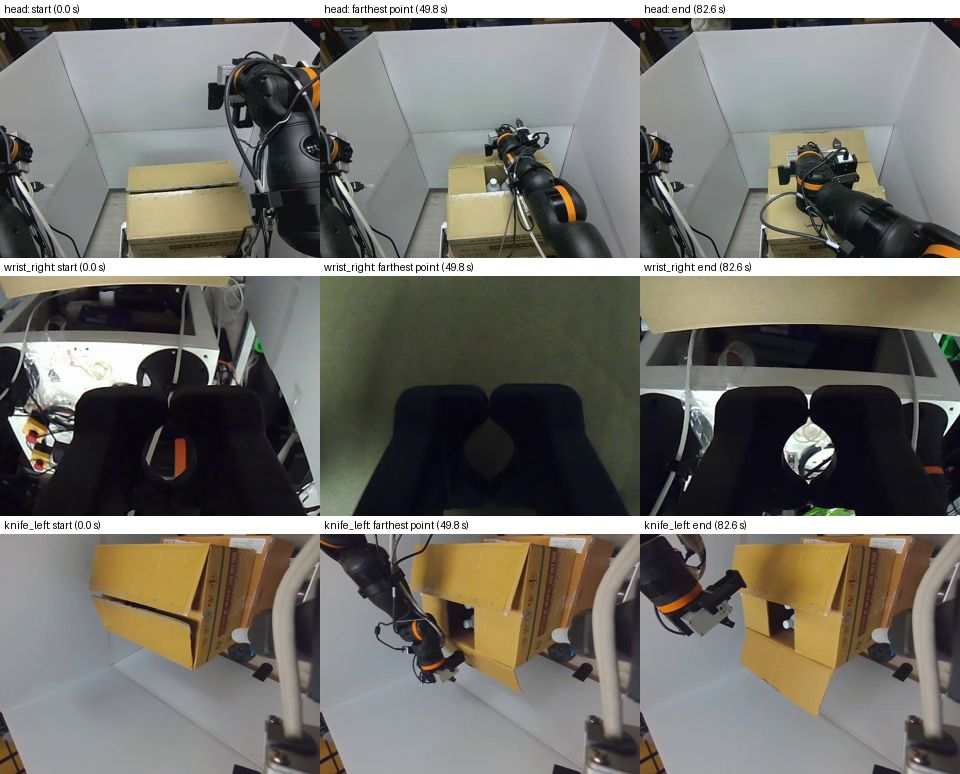

**front**: episode 15, from `dataset_20261126/thor_box_flapfront_newmovement1` (recorded episode 4)

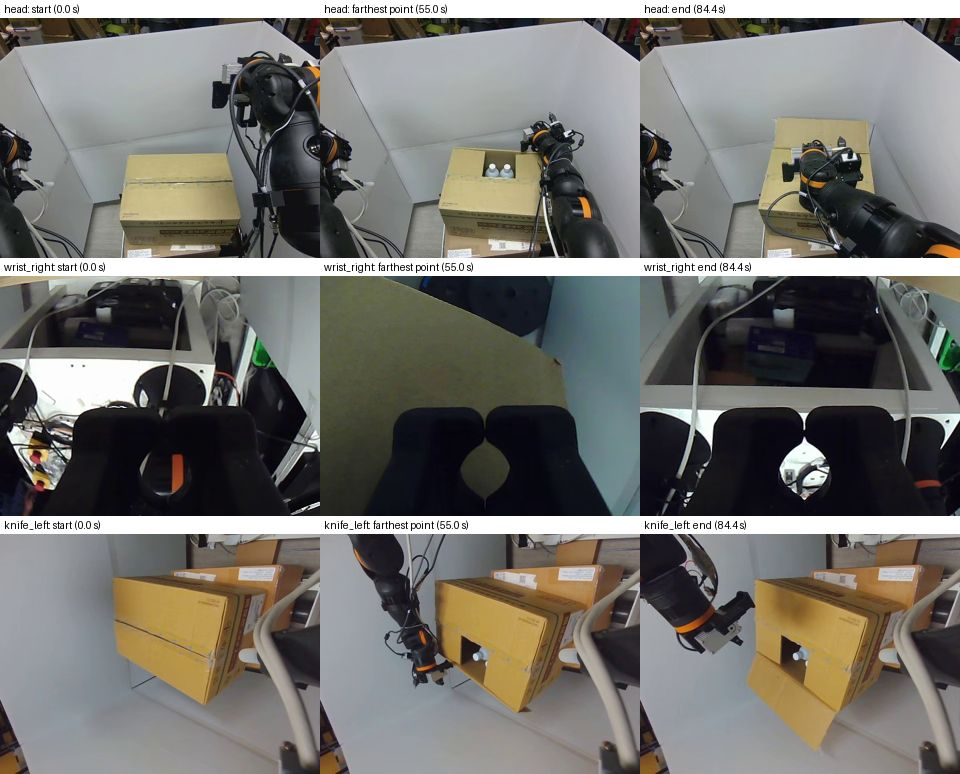

**back**: episode 24, from `thor_box2_back` (recorded episode 8)

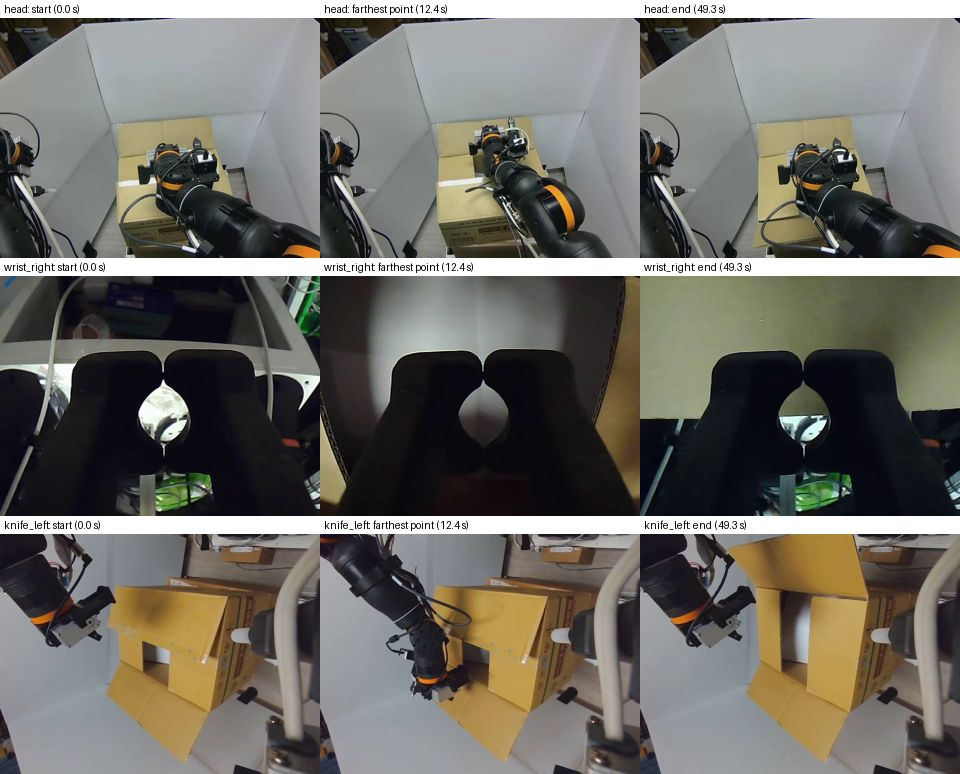

**back**: episode 38, from `thor_test1_back` (recorded episode 8)

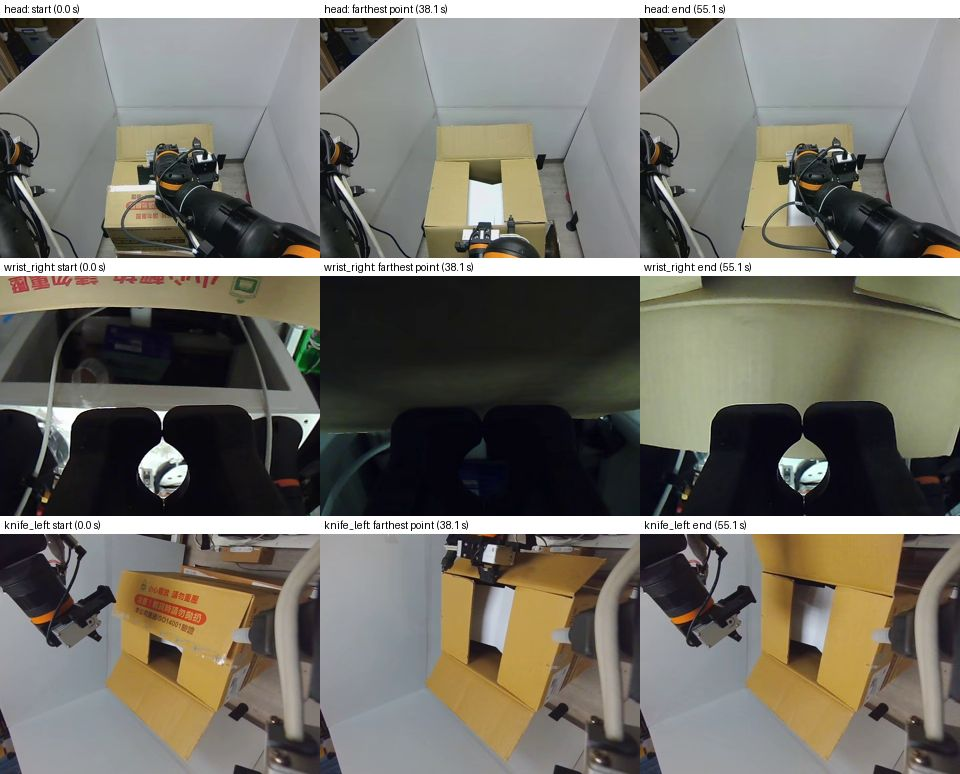

**left**: episode 48, from `dataset_v2/thor_box_flapleft_newmovement` (recorded episode 3)

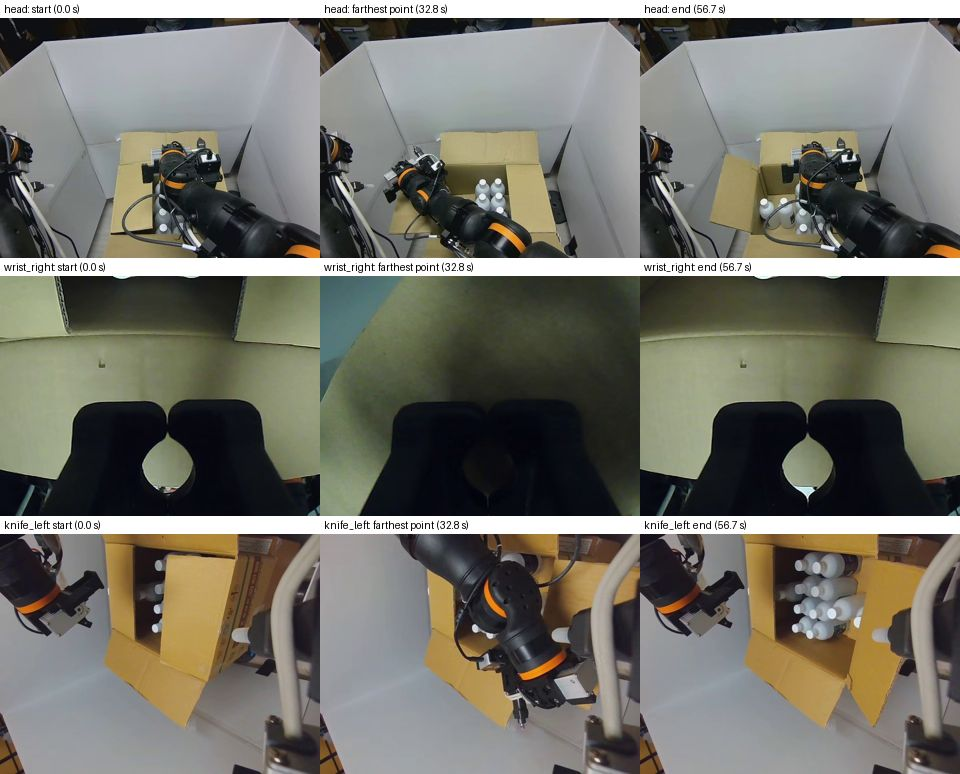

**right**: episode 55, from `dataset_v2/thor_box_flapright_newmovement` (recorded episode 3)

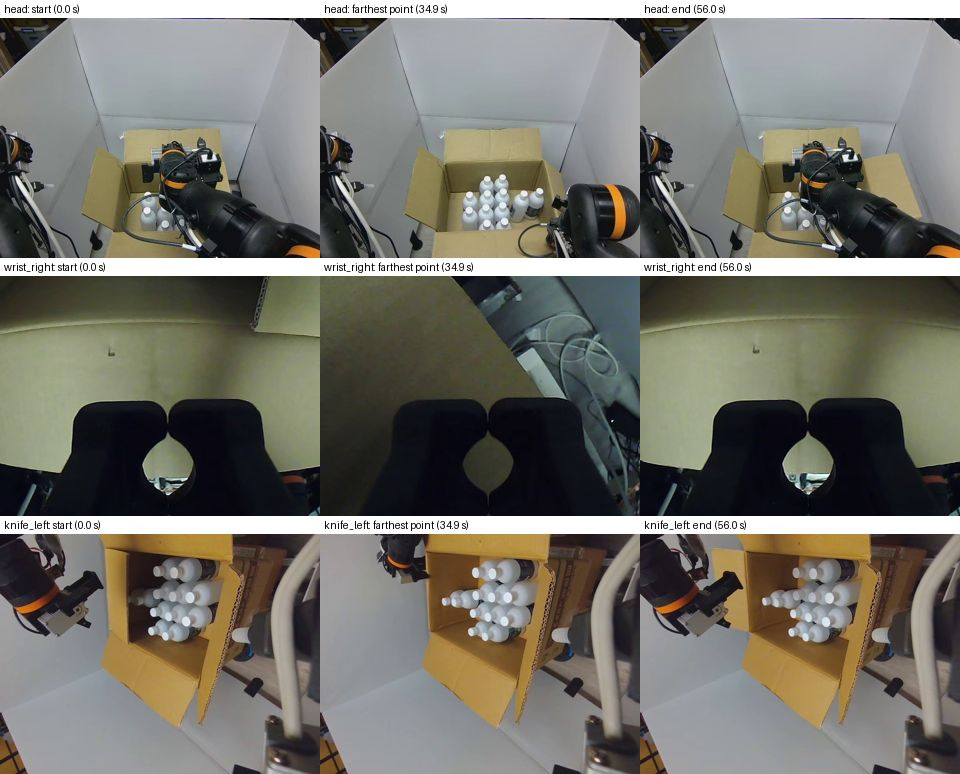

**left**: episode 70, from `dataset_20261126/thor_box_flapright_newmovement` (recorded episode 7)

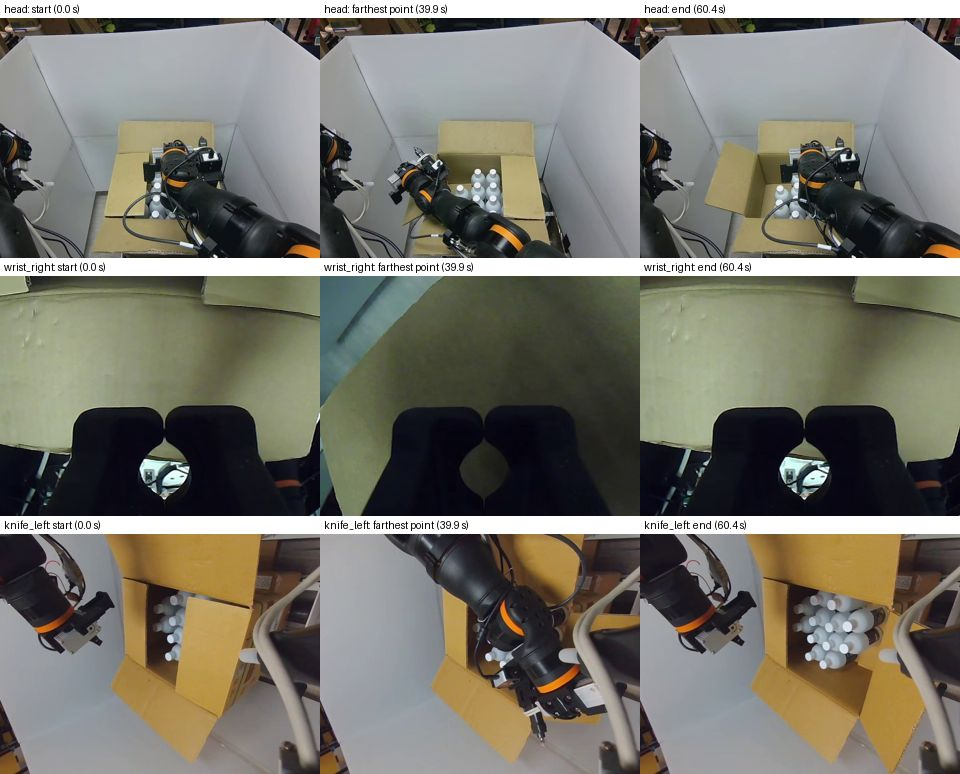

**right**: episode 71, from `dataset_20261126/thor_box_flapright_newmovement` (recorded episode 7)

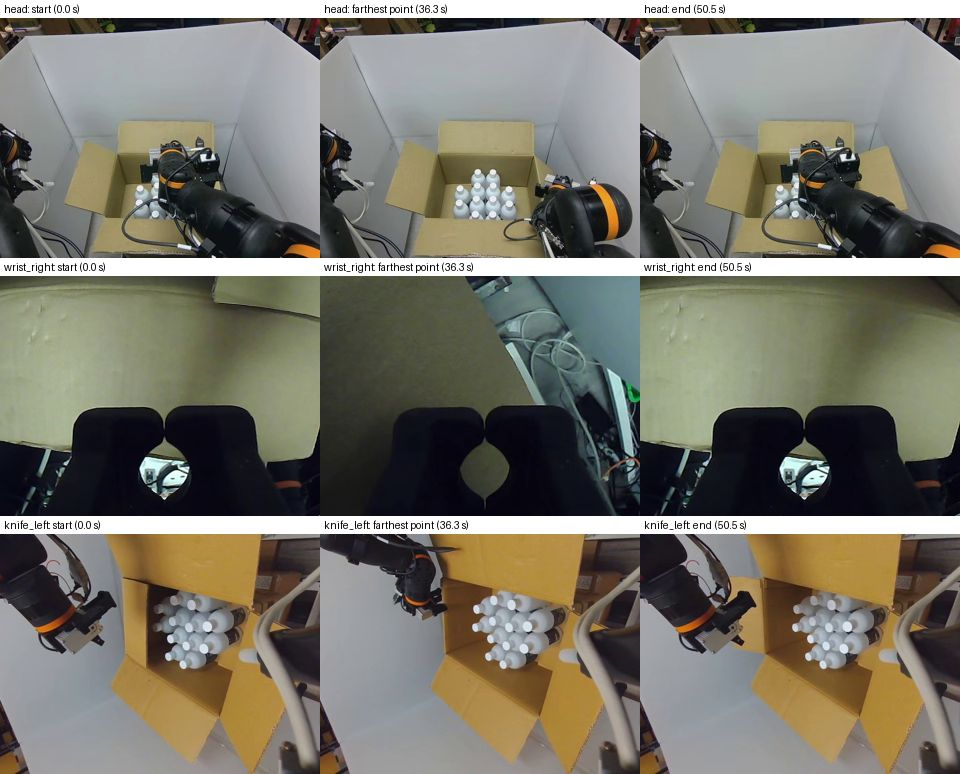

In [16]:
from PIL import Image as PILImage, ImageDraw
from lerobot.datasets.lerobot_dataset import LeRobotDataset

ds = LeRobotDataset(spec["repo_id"], root=ROOT)
W, H, LBL = 320, 240, 18
for e in split["train_probe"]:
    s = EPISODES[e]["state"]
    far = np.minimum(np.abs(s - s[0]).mean(axis=1), np.abs(s - s[-1]).mean(axis=1))
    moments = [("start", 0), ("farthest point", int(np.argmax(far))), ("end", len(s) - 1)]
    sheet = PILImage.new("RGB", (len(moments) * W, len(cams) * (H + LBL)), "white")
    draw = ImageDraw.Draw(sheet)
    for c, (label, k) in enumerate(moments):
        item = ds[EPISODES[e]["first_index"] + k]
        for r, cam_name in enumerate(cams):
            t = item[f"observation.images.{cam_name}"]
            img = (t.permute(1, 2, 0).float().numpy() * (255 if t.dtype.is_floating_point else 1)).clip(0, 255)
            sheet.paste(PILImage.fromarray(img.astype(np.uint8)).resize((W, H)), (c * W, r * (H + LBL) + LBL))
            draw.text((c * W + 4, r * (H + LBL) + 3), f"{cam_name}: {label} ({k / FPS:.1f} s)", fill="black")
    buf = io.BytesIO()
    sheet.save(buf, format="JPEG", quality=80)
    display(Markdown(f"**{EPISODES[e]['flap']}**: episode {e}, from `{SOURCE[e]['folder']}` "
                     f"(recorded episode {SOURCE[e]['recorded_episode']})"))
    display(Image(data=buf.getvalue(), format="jpeg"))

## 13. Dropped episodes

What `drop` in the YAML leaves out, with the reason given there. "0 right" is one flap of a left-then-right
recording; a number alone is the whole recorded episode.

In [17]:
rank = {f: i for i, f in enumerate(ORDER)}
display(DROPPED.assign(flap=DROPPED.flaps.map(" + ".join), _rank=DROPPED.flaps.map(lambda fl: rank.get(fl[0], len(ORDER))))
        .sort_values(["_rank", "folder", "recorded_ep"])
        .set_index(["flap", "folder", "recorded_ep"])[["reason"]])

reason
flap         folder                                           recorded_ep                                                                                                                         
front        dataset_20261126/thor_box_flapfront_newmovement1 1            works the half-open flap for ~30 s, and a hand reaches into the box at the end; path least like the other front epis...
                                                              2                                                                                    cut off before the arm is back at the rest pose
             dataset_v2/thor_box_front_newmovement            0                      opens the flap but stays at the box and never returns to the rest pose; its path is the least like the others
                                                              13                                                                                      cut off after 12 s, the flap is still closed
back         thor_box2_back                                   0                                                                                       cut off after 10 s, the flap is still closed
                                                              1                                                      approaches the flap along a path none of the other 27 back-flap episodes uses
             thor_test1_back                                  0                                    first episode of the session, keeps pushing the open flap ~30 s before going to the finish pose
left + right dataset_20261126/thor_box_flapright_newmovement  2                                    goes from the left flap straight to the right one without returning to the rest pose in between
right        dataset_20261126/thor_box_flapright_newmovement  0 right                                                                              cut off before the arm is back at the rest pose